# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Andini Febrina
- **Email:** andinifebrina266@gmail.com
- **ID Dicoding:** ds322b6x0189

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh cuaca dan musim terhadap jumlah penyewaan sepeda sepanjang tahun 2012, dan berapa persentase penurunan rata-rata penyewaan saat cuaca buruk dibandingkan cuaca cerah?
- **Pertanyaan 2:** Pada jam berapa puncak penyewaan sepeda terjadi antara pengguna biasa (casual) dan pengguna terdaftar (registered) pada hari kerja sepanjang tahun 2011-2012?
- **Pertanyaan 3:** Berapa persentase pertumbuhan bulanan penyewaan sepeda dari tahun 2011 ke 2012, dan bulan apa yang mencatatkan penyewaan tertinggi di tahun 2012?
- **Pertanyaan 4:** Bagaimana perbedaan proporsi pengguna casual dan registered pada hari kerja dibandingkan akhir pekan sepanjang tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [9]:
# Import Library

import os
import glob
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df_day

In [10]:
# Memuat tabel day

df_day = pd.read_csv("data/day.csv")
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Tabel df_day berhasil dimuat dengan baik dan berisi data penyewaan sepeda yang telah diagregasi dalam skala harian.  
- Terdiri dari 16 kolom yang memuat informasi tanggal (dteday), musim (season), kondisi cuaca (weathersit), parameter lingkungan (temp, atemp, hum, windspeed), serta jumlah penyewaan berdasarkan tipe pengguna (casual, registered, cnt).
- Data mencatat bahwa nilai cnt merupakan hasil penjumlahan langsung dari variabel casual dan registered (misal baris pertama: $331 + 654 = 985$).  

#### Load df_hour

In [11]:
# Memuat tabel hour

df_hour = pd.read_csv("data/hour.csv")
df_hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Tabel df_hour berhasil dimuat dan berisi data penyewaan sepeda dengan tingkat granularitas yang lebih detail, yaitu per jam (hr dari 0 hingga 23).   
- Memiliki struktur kolom yang serupa dengan day_df, namun terdapat tambahan kolom hr untuk mengamati pola aktivitas transaksi harian secara spesifik.
- Nilai variabel temp, atemp, hum, dan windspeed sudah berada dalam bentuk yang dinormalisasi (rentang 0 hingga 1).

### Assessing Data

#### Identifying df day problem

In [12]:
# Info tabel day
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [13]:
# Mengidentifikasi missing value
df_day.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [14]:
# Mengidentifikasi data duplikat
print("Jumlah duplikasi: ", df_day.duplicated().sum())

Jumlah duplikasi:  0


In [15]:
# Summary data
df_day.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Insight:**
- Beberapa nama variabel menggunakan penamaan yang terpotong atau berupa singkatan teknis seperti dteday, yr, mnth, hr, weathersit, hum, atemp, dan cnt. Penamaan ini agak membingungkan dan akan terlihat kurang jelas saat divisualisasikan.
- Variabel dteday terdeteksi bertipe data object (string), padahal variabel ini berisi data tanggal yang seharusnya bertipe datetime.
- Variabel season, yr, mnth, holiday, weekday, workingday, dan weathersit masih terdaftar dengan tipe data numerik (int64), padahal variabel-variabel ini merupakan data kategorikal.
- Seluruh 731 baris terisi penuh, sehingga tidak ditemukan missing value.
- Tidak terdapat data duplikat.

**Steps to Take:**
1. Mengganti nama variabel:

    - dteday $\rightarrow$ dateday

    - yr $\rightarrow$ year

    - mnth $\rightarrow$ month

    - hr $\rightarrow$ hour

    - weathersit $\rightarrow$ weather_cond

    - temp $\rightarrow$ temperature

    - atemp $\rightarrow$ feeling_temperature

    - hum $\rightarrow$ humidity

    - casual $\rightarrow$ casual_users

    - registered $\rightarrow$ registered_users

    - cnt $\rightarrow$ total_count
2. Mengubah tipe data kolom dateday dari object menjadi datetime menggunakan pd.to_datetime()
3. Mengubah tipe data variabel kategorikal dari int64 menjadi category.
4. Melakukan pemetaan (mapping) nilai numerik ke bentuk teks/label deskriptif:
    - season: 1 $\rightarrow$ 'Spring', 2 $\rightarrow$ 'Summer', 3 $\rightarrow$ 'Fall', 4 $\rightarrow$ 'Winter'
    - weather_cond: 1 $\rightarrow$ 'Clear', 2 $\rightarrow$ 'Mist', 3 $\rightarrow$ 'Rain', 4 $\rightarrow$ 'Heavy'
    - year: 0 $\rightarrow$ '2011', 1 $\rightarrow$ '2012'
    - month: 1-12 $\rightarrow$ 'Jan' hingga 'Dec'
    - weekday: 0-6 $\rightarrow$ 'Sun' hingga 'Sat'
    - workingday & holiday: 0 $\rightarrow$ 'No', 1 $\rightarrow$ 'Yes'




#### Identifying df_hour problem

In [16]:
# Info tabel day
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [17]:
# Mengidentifikasi missing value
df_hour.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [18]:
# Mengidentifikasi data duplikat
print("Jumlah duplikasi: ", df_hour.duplicated().sum())

Jumlah duplikasi:  0


In [19]:
# Summary data
df_hour.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Insight:**
- Variabel dteday terdeteksi bertipe data object (string), padahal variabel ini berisi data tanggal yang seharusnya bertipe datetime.
- Variabel season, yr, mnth, hr, holiday, weekday, workingday, dan weathersit masih terdaftar dengan tipe data numerik (int64), padahal variabel-variabel ini merupakan data kategorikal.
- Seluruh 17379 baris terisi penuh, sehingga tidak ditemukan missing value.
- Beberapa nama variabel menggunakan penamaan yang terpotong atau berupa singkatan teknis sepertiyr, mnth, hr, weathersit, hum, atemp, dan cnt. Penamaan ini agak membingungkan dan akan terlihat kurang jelas saat divisualisasikan.
- Berbeda dengan data harian (df_day) yang batas maksimal cuacanya hanya kategori 3, pada rangkuman df_hour terdapat kategori weathersit yang mencapai nilai maksimum 4 (Heavy Rain/Severe Weather). Ini masuk akal, mengingat cuaca ekstrem lebih mungkin tercatat selama satu atau beberapa jam tertentu dibandingkan bertahan sepanjang hari.

**Steps to Take:**
1. Mengganti nama variabel:

    - dteday $\rightarrow$ dateday

    - yr $\rightarrow$ year

    - mnth $\rightarrow$ month

    - hr $\rightarrow$ hour

    - weathersit $\rightarrow$ weather_cond

    - temp $\rightarrow$ temperature

    - atemp $\rightarrow$ feeling_temperature

    - hum $\rightarrow$ humidity

    - casual $\rightarrow$ casual_users

    - registered $\rightarrow$ registered_users

    - cnt $\rightarrow$ total_count
2. Mengubah tipe data kolom dateday dari object menjadi datetime menggunakan pd.to_datetime()
3. Mengubah tipe data variabel kategorikal dari int64 menjadi category.
4. Melakukan pemetaan (mapping) nilai numerik ke bentuk teks/label deskriptif:
    - season: 1 $\rightarrow$ 'Spring', 2 $\rightarrow$ 'Summer', 3 $\rightarrow$ 'Fall', 4 $\rightarrow$ 'Winter'
    - weather_cond: 1 $\rightarrow$ 'Clear', 2 $\rightarrow$ 'Mist', 3 $\rightarrow$ 'Rain', 4 $\rightarrow$ 'Heavy'
    - year: 0 $\rightarrow$ '2011', 1 $\rightarrow$ '2012'
    - month: 1-12 $\rightarrow$ 'Jan' hingga 'Dec'
    - weekday: 0-6 $\rightarrow$ 'Sun' hingga 'Sat'
    - workingday & holiday: 0 $\rightarrow$ 'No', 1 $\rightarrow$ 'Yes'



### Cleaning Data

#### Fixing df_day problem

In [20]:
# 1. Mengganti nama variabel (Renaming Columns)
rename_dict = {
    'dteday': 'dateday',
    'yr': 'year',
    'mnth': 'month',
    'weathersit': 'weather_cond',
    'temp': 'temperature',
    'atemp': 'feeling_temperature',
    'hum': 'humidity',
    'casual': 'casual_users',
    'registered': 'registered_users',
    'cnt': 'total_count'
}
df_day.rename(columns=rename_dict, inplace=True)

In [21]:
# 2. Mengubah tipe data kolom dateday dari object menjadi datetime
df_day['dateday'] = pd.to_datetime(df_day['dateday'])

In [22]:
# 3 & 4. Mengubah tipe data menjadi category dan melakukan mapping nilai
# Mapping untuk season
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
df_day['season'] = df_day['season'].map(season_mapping).astype('category')

# Mapping untuk weather_cond
weather_mapping = {1: 'Clear', 2: 'Mist', 3: 'Rain', 4: 'Heavy'}
df_day['weather_cond'] = df_day['weather_cond'].map(weather_mapping).astype('category')

# Mapping untuk year
year_mapping = {0: '2011', 1: '2012'}
df_day['year'] = df_day['year'].map(year_mapping).astype('category')

# Mapping untuk month
month_mapping = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
df_day['month'] = df_day['month'].map(month_mapping).astype('category')

# Mapping untuk weekday (0: Minggu s/d 6: Sabtu)
weekday_mapping = {
    0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'
}
df_day['weekday'] = df_day['weekday'].map(weekday_mapping).astype('category')

# Mapping untuk workingday dan holiday (0: No, 1: Yes)
binary_mapping = {0: 'No', 1: 'Yes'}
df_day['workingday'] = df_day['workingday'].map(binary_mapping).astype('category')
df_day['holiday'] = df_day['holiday'].map(binary_mapping).astype('category')


In [23]:
# Mengecek info data setelah dibersihkan
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   instant              731 non-null    int64         
 1   dateday              731 non-null    datetime64[ns]
 2   season               731 non-null    category      
 3   year                 731 non-null    category      
 4   month                731 non-null    category      
 5   holiday              731 non-null    category      
 6   weekday              731 non-null    category      
 7   workingday           731 non-null    category      
 8   weather_cond         731 non-null    category      
 9   temperature          731 non-null    float64       
 10  feeling_temperature  731 non-null    float64       
 11  humidity             731 non-null    float64       
 12  windspeed            731 non-null    float64       
 13  casual_users         731 non-null  

In [24]:
# Mengecek data setelah dibersihkan
df_day.head()

,instant,dateday,season,year,month,holiday,weekday,workingday,weather_cond,temperature,feeling_temperature,humidity,windspeed,casual_users,registered_users,total_count
0,1,2011-01-01,Spring,2011,Jan,No,Sat,No,Mist,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,Jan,No,Sun,No,Mist,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,Jan,No,Mon,Yes,Clear,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,Jan,No,Tue,Yes,Clear,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,Jan,No,Wed,Yes,Clear,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Nama variabel telah berhasil diubah menjadi lebih jelas dan informatif.
- Variabel dateday telah berhasil diubah menjadi tipe datetime64[ns].
- Variabel season, year, month, holiday, weekday, workingday, dan weather_cond telah berhasil diubah menjadi tipe data category.
- Variabel season, year, month, holiday, weekday, workingday, dan weather_cond berhasil dipetakan dari angka (integer) menjadi label teks.

In [25]:
# Menyimpan data yang sudah dibersihkan
df_day.to_csv("main_data_day.csv", index=False)

#### Fixing df_hour problem

In [26]:
# 1. Mengganti nama variabel (Renaming Columns)
rename_dict_hour = {
    'dteday': 'dateday',
    'yr': 'year',
    'mnth': 'month',
    'hr': 'hour', # Tambahan untuk df_hour
    'weathersit': 'weather_cond',
    'temp': 'temperature',
    'atemp': 'feeling_temperature',
    'hum': 'humidity',
    'casual': 'casual_users',
    'registered': 'registered_users',
    'cnt': 'total_count'
}
df_hour.rename(columns=rename_dict_hour, inplace=True)

In [27]:
# 2. Mengubah tipe data kolom dateday dari object menjadi datetime
df_hour['dateday'] = pd.to_datetime(df_hour['dateday'])

In [28]:
# 3 & 4. Mengubah tipe data menjadi category dan melakukan mapping nilai
# Mapping untuk season
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
df_hour['season'] = df_hour['season'].map(season_mapping).astype('category')

# Mapping untuk weather_cond
weather_mapping = {1: 'Clear', 2: 'Mist', 3: 'Rain', 4: 'Heavy'}
df_hour['weather_cond'] = df_hour['weather_cond'].map(weather_mapping).astype('category')

# Mapping untuk year
year_mapping = {0: '2011', 1: '2012'}
df_hour['year'] = df_hour['year'].map(year_mapping).astype('category')

# Mapping untuk month
month_mapping = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
df_hour['month'] = df_hour['month'].map(month_mapping).astype('category')

# Mapping untuk weekday
weekday_mapping = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
df_hour['weekday'] = df_hour['weekday'].map(weekday_mapping).astype('category')

# Mapping untuk working day
binary_mapping = {0: 'No', 1: 'Yes'}
df_hour['workingday'] = df_hour['workingday'].map(binary_mapping).astype('category')

# Mapping untuk holiday
df_hour['holiday'] = df_hour['holiday'].map(binary_mapping).astype('category')

# Mengubah kolom hour menjadi tipe data category
df_hour['hour'] = df_hour['hour'].astype('category')

In [29]:
# Mengecek info data setelah dibersihkan
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   instant              17379 non-null  int64         
 1   dateday              17379 non-null  datetime64[ns]
 2   season               17379 non-null  category      
 3   year                 17379 non-null  category      
 4   month                17379 non-null  category      
 5   hour                 17379 non-null  category      
 6   holiday              17379 non-null  category      
 7   weekday              17379 non-null  category      
 8   workingday           17379 non-null  category      
 9   weather_cond         17379 non-null  category      
 10  temperature          17379 non-null  float64       
 11  feeling_temperature  17379 non-null  float64       
 12  humidity             17379 non-null  float64       
 13  windspeed            17379 non-

In [30]:
# Mengecek data setelah dibersihkan
df_hour.head()

,instant,dateday,season,year,month,hour,holiday,weekday,workingday,weather_cond,temperature,feeling_temperature,humidity,windspeed,casual_users,registered_users,total_count
0,1,2011-01-01,Spring,2011,Jan,0,No,Sat,No,Clear,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,Spring,2011,Jan,1,No,Sat,No,Clear,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,Spring,2011,Jan,2,No,Sat,No,Clear,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,Spring,2011,Jan,3,No,Sat,No,Clear,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,Spring,2011,Jan,4,No,Sat,No,Clear,0.24,0.2879,0.75,0.0,0,1,1


Insight:

- Nama variabel telah berhasil diubah menjadi lebih jelas dan informatif.
- Variabel dateday telah berhasil diubah menjadi tipe datetime64[ns].
- Variabel season, year, month, hour, holiday, weekday, workingday, dan weather_cond telah berhasil diubah menjadi tipe data category.
- Variabel season, year, month, holiday, weekday, workingday, dan weather_cond berhasil dipetakan dari angka (integer) menjadi label teks.

In [31]:
# Menyimpan data yang sudah dibersihkan
df_hour.to_csv("main_data_hour.csv", index=False)

## Exploratory Data Analysis (EDA)

### Explore df_day

In [32]:
# Summary statistik variabel numerik
df_day.describe()

,instant,dateday,temperature,feeling_temperature,humidity,windspeed,casual_users,registered_users,total_count
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [33]:
# Summary statistik variabel kategorik
df_day.describe(include=['category'])

,season,year,month,holiday,weekday,workingday,weather_cond
count,731,731,731,731,731,731,731
unique,4,2,12,2,7,2,3
top,Fall,2012,Aug,No,Mon,Yes,Clear
freq,188,366,62,710,105,500,463


**Insight:**

**1. Skala & Distribusi Volume Penyewaan Harian**
- Terjadi rata-rata 4.504 penyewaan per hari, dengan rentang fluktuasi dari terendah 22 penyewaan hingga tertinggi 8.714 penyewaan dalam satu hari.
- Nilai mean (4.504) dan nilai median (4.548) berada pada angka yang sangat dekat, menunjukkan bahwa distribusi data volume harian cenderung normal.

**2. Pengguna**

 Pengguna terdaftar registered() memiliki rata-rata 3.656 penyewaan/hari, sedangkan pengguna kasual (casual) memiliki rata-rata 848 penyewaan/hari. Namun, angka maksimum casual mencapai 3.410 penyewaan pada hari-hari tertentu (biasanya di akhir pekan).

**3. Kondisi Lingkungan & Cuaca**
- Cuaca Cerah (Clear) merupakan kondisi cuaca yang paling banyak terdata selama rentang 2 tahun, yaitu terjadi sebanyak 463 hari dari 731 hari.
- Musim Gugur (Fall) adalah musim yang paling banyak terdata yaitu sebanyak 188 hari.
- Rata-rata suhu terbilang hangat (skala normalisasi rata-rata 0,49) dengan tingkat kelembapan udara rata-rata berada di angka 62,8%.

**4. Hari Operasional**
- Sebagian besar rentang waktu data terdiri dari hari kerja biasa, yaitu terjadi sebanyak 500 hari dari 731 hari.
- Hari libur resmi nasional (official holiday) sangat sedikit, hanya terjadi sebanyak 21 hari (731 hari - 710 hari holiday = 'No').

In [34]:
# Filter data khusus tahun 2012
df_day_2012 = df_day[df_day['year'] == '2012']

In [35]:
# Rata-rata & total penyewaan berdasarkan kondisi cuaca
weather_impact = df_day_2012.groupby('weather_cond', observed=False)['total_count'].agg(['mean', 'max', 'min', 'sum'])
print("--- Analisis Cuaca (2012) ---")
display(weather_impact)

--- Analisis Cuaca (2012) ---


,mean,max,min,sum
weather_cond,,,,
Clear,6003.734177,8714,1529,1422885
Mist,4991.333333,8362,920,613934
Rain,2126.166667,4639,22,12757


In [36]:
# Menghitung % penurunan rata-rata penyewaan dari cuaca Clear ke Rain
clear_mean = weather_impact.loc['Clear', 'mean']
rain_mean = weather_impact.loc['Rain', 'mean']
pct_drop = ((clear_mean - rain_mean) / clear_mean) * 100
print(f"Penurunan rata-rata penyewaan saat Rain dibanding Clear: {pct_drop:.2f}%")

Penurunan rata-rata penyewaan saat Rain dibanding Clear: 64.59%


In [37]:
# Rata-rata & total penyewaan berdasarkan musim
season_impact = df_day_2012.groupby('season', observed=False)['total_count'].agg(['mean', 'max', 'min', 'sum'])
print("\n--- Analisis Musim (2012) ---")
display(season_impact)


--- Analisis Musim (2012) ---


,mean,max,min,sum
season,,,,
Fall,6824.244681,8714,4073,641479
Spring,3531.296703,7836,441,321348
Summer,6209.489130,8362,1027,571273
Winter,5791.865169,8555,22,515476


**Insight:**

**1. Dampak Kondisi Cuaca**
- Rata-rata penyewaan harian tertinggi terjadi saat cuaca cerah, yaitu mencapai 6.004 unit/hari dengan total akumulasi 1.422.885 penyewaan sepanjang tahun 2012.  
-  Terjadi penurunan rata-rata penyewaan sepeda yang sangat signifikan sebesar 64,59% ketika cuaca hujan (Rain = 2.126 unit/hari) jika dibandingkan dengan cuaca cerah (Clear = 6.004 unit/hari). Bahkan penyewaan harian terendah di tahun 2012 terjadi saat cuaca hujan (hanya 22 sepeda dalam sehari).
- Cuaca berkabut(Mist) sedikit menurunkan minat pengguna, namun volumenya relatif stabil dengan rata-rata 4.991 unit/hari.

**2. Dampak Musim**
- Musim Gugur(Fall) menjadi musim paling diminati untuk bersepeda di tahun 2012 dengan rata-rata penyewaan tertinggi sebesar 6.824 unit/hari dengan total akumulasi 641.479 penyewaan. Angka penyewaan harian tertinggi di tahun 2012 (8.714 unit) juga dicapai pada musim ini.
- Musim Panas menempati posisi kedua dengan rata-rata 6.209 unit/hari, diikuti Musim Dingin yang masih cukup tinggi di angka 5.792 unit/hari.
- Penyewaan di Musim Semi(Spring) menjadi yang terendah di tahun 2012 dengan rata-rata 3.531 unit/hari.

In [38]:
# Aggregasi total penyewaan berdasarkan tahun dan bulan
monthly_rentals = df_day.groupby(['year', 'month'], observed=False)['total_count'].sum().unstack(level=0)
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_rentals = monthly_rentals.reindex(month_order)
display(monthly_rentals)

year,2011,2012
month,,
Jan,38189,96744
Feb,48215,103137
Mar,64045,164875
Apr,94870,174224
May,135821,195865
Jun,143512,202830
Jul,141341,203607
Aug,136691,214503
Sep,127418,218573


In [39]:
# Menghitung persentase pertumbuhan bulanan 2011 ke 2012
monthly_rentals['growth_pct'] = ((monthly_rentals['2012'] - monthly_rentals['2011']) / monthly_rentals['2011']) * 100
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_rentals = monthly_rentals.reindex(month_order)
print("\n--- Tabel Pertumbuhan Bulanan (2011 vs 2012) ---")
display(monthly_rentals)


--- Tabel Pertumbuhan Bulanan (2011 vs 2012) ---


year,2011,2012,growth_pct
month,,,
Jan,38189,96744,153.329493
Feb,48215,103137,113.910609
Mar,64045,164875,157.436178
Apr,94870,174224,83.644988
May,135821,195865,44.208186
Jun,143512,202830,41.333129
Jul,141341,203607,44.053742
Aug,136691,214503,56.925474
Sep,127418,218573,71.540128


In [40]:
# Bulan puncak penyewaan di tahun 2012
peak_month_2012 = monthly_rentals['2012'].idxmax()
peak_value_2012 = monthly_rentals['2012'].max()
print(f"Bulan dengan penyewaan tertinggi di 2012 adalah bulan {peak_month_2012} sebanyak {peak_value_2012:,} unit.")

Bulan dengan penyewaan tertinggi di 2012 adalah bulan Sep sebanyak 218,573 unit.


**Insight:**
- Seluruh bulan pada tahun 2012 mengalami peningkatan jumlah penyewaan dibandingkan bulan yang sama di tahun 2011. Tidak ada satu bulan pun yang mengalami penurunan kinerja.
- Persentase kenaikan terbesar terjadi pada bulan Maret yaitu sebesar 157,44%, Januari sebesar 153,33%, dan Februari sebesar 113,91%. Ini menunjukkan bahwa terjadi lonjakan pengguna baru yang sangat cepat di awal tahun 2012 dibanding awal tahun 2011.
- Pada tahun 2011, puncak volume penyewaan tertinggi terjadi pada bulan Juni (143.512 unit). Sedangkan di tahun 2012, puncak penyewaan bergeser ke bulan September (218.573 unit).
- Kedua tahun memperlihatkan tren penyewaan yang sama, yaitu penyewaan paling rendah terjadi di awal tahun (Januari-Februari), naik pesat mulai pertengahan tahun hingga awal musim gugur (Mei-Oktober), dan perlahan menurun menjelang akhir tahun (November-Desember).

In [41]:
# Pengelompokan total & rata-rata pengguna berdasarkan status hari kerja
workingday_analysis = df_day_2012.groupby('workingday', observed=False)[['casual_users', 'registered_users', 'total_count']].agg(['sum', 'mean'])
display(workingday_analysis)

casual_users              registered_users               \
                    sum         mean              sum         mean   
workingday                                                           
No               187834  1619.258621           425596  3668.931034   
Yes              184931   739.724000          1251215  5004.860000   

           total_count               
                   sum         mean  
workingday                           
No              613430  5288.189655  
Yes            1436146  5744.584000

In [42]:
# Menghitung proporsi persentase casual vs registered per kategori hari
workingday_sum = df_day_2012.groupby('workingday', observed=False)[['casual_users', 'registered_users']].sum()
workingday_prop = workingday_sum.div(workingday_sum.sum(axis=1), axis=0) * 100
print("\n--- Proporsi Persentase (%) Casual vs Registered ---")
display(workingday_prop)


--- Proporsi Persentase (%) Casual vs Registered ---


,casual_users,registered_users
workingday,,
No,30.620283,69.379717
Yes,12.876894,87.123106


**Insight:**
- Rata-rata total penyewaan harian pada hari kerja mencapai 5.745 unit/hari, lebih tinggi dibandingkan saat hari libur sebesar 5.288 unit/hari.
- Pengguna terdaftar mencapai puncaknya pada hari kerja dengan rata-rata 5.005 unit/hari, menyumbang 87,12% dari seluruh penyewaan pada kategori hari tersebut. Angka ini naik drastis dari rata-rata hari libur sebesar 3.669 unit/hari.
- Aktivitas pengguna kasual meningkat lebih dari dua kali lipat pada hari libur/akhir pekan, dari rata-rata 740 unit/hari di hari kerja menjadi 1.619 unit/hari. Proporsinya pun melonjak dari 12,88% pada hari kerja menjadi 30,62% pada hari libur.

In [43]:
# Menghitung korelasi variabel lingkungan terhadap 'total_count'
env_vars = ['temperature', 'feeling_temperature', 'humidity', 'windspeed']
env_corr = df_day[env_vars].corrwith(df_day['total_count']).to_frame(name='korelasi_total_count')

# Mengurutkan dari korelasi terbesar ke terkecil
env_corr = env_corr.sort_values(by='korelasi_total_count', ascending=False)
display(env_corr)

,korelasi_total_count
feeling_temperature,0.631066
temperature,0.627494
humidity,-0.100659
windspeed,-0.234545


**Insight:**
- Variabel feeling_temperature (0,631) dan temperature (0,627) memiliki nilai korelasi positif paling tinggi terhadap total penyewaan. Hal ini berarti semakin hangat suhu udara yang dirasakan pengguna, semakin tinggi jumlah sepeda yang disewa.
- Variabel windspeed (-0,235) memiliki nilai korelasi negatif terhadap total penyewaan, hal ini berarti semakin kencang angin bertiup, jumlah penyewaan sepeda cenderung sedikit menurun.
- humidity (-0,101) memiliki nilai korelasi negatif dan paling mendekati nol.  Hal ini berarti meningkatnya kelembapan udara tidak berdampak signifikan terhadap keputusan pengguna untuk menyewa sepeda dibanding faktor suhu dan angin.


### Explore df_hour

In [44]:
# Summary statistik variabel numerik
df_hour.describe()

,instant,dateday,temperature,feeling_temperature,humidity,windspeed,casual_users,registered_users,total_count
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


In [45]:
# Summary statistik variabel kategorik
df_hour.describe(include=['category'])

,season,year,month,hour,holiday,weekday,workingday,weather_cond
count,17379,17379,17379,17379,17379,17379,17379,17379
unique,4,2,12,24,2,7,2,4
top,Fall,2012,Jul,17,No,Sat,Yes,Clear
freq,4496,8734,1488,730,16879,2512,11865,11413


**Insight:**
- Secara keseluruhan, terdapat rata-rata 189 sepeda yang disewa setiap jamnya.
- Jumlah penyewaan yang paling sepi yaitu 1 sepeda/jam hingga yang paling ramai mencapai 977 sepeda/jam.
- Pengguna terdaftar (registered) menyumbang rata-rata 153,79 penyewaan/jam, sedangkan pengguna biasa (casual) hanya menyumbang rata-rata 35,68 penyewaan/jam.

In [46]:
# Rata-rata penyewaan per jam berdasarkan segmen pengguna
hourly_pattern = df_hour.groupby('hour', observed=False)[['casual_users', 'registered_users', 'total_count']].mean()
display(hourly_pattern)

,casual_users,registered_users,total_count
hour,,,
0,10.158402,43.739669,53.898072
1,6.504144,26.871547,33.375691
2,4.772028,18.097902,22.869930
3,2.715925,9.011478,11.727403
4,1.253945,5.098996,6.352941
5,1.411437,18.478382,19.889819
6,4.161379,71.882759,76.044138
7,11.055021,201.009629,212.064649
8,21.679505,337.331499,359.011004


**Insight:**


**1. Jam Puncak (Peak Hours) dan Jam Tersepi (Off-Peak)**
- Titik tertinggi penyewaan sepeda terjadi pada jam 17.00 yaitu sebanyak 461 unit/jam dan pada jam 18.00 sebanyak 425 unit/jam.
- Terjadi lonjakan tinggi penyewaan sepeda kedua pada jam 08.00 pagi yaitu sebanyak 359 unit/jam.
- Aktivitas penyewaan berada di titik terendah pada dini hari, khususnya pada jam 04.00 pagi yaitu sebanyak 6 unit/jam dan pada jam 03.00 pagi sebanyak 11 unit/jam.

**2. Pola Jam Aktif Pengguna**
- Pengguna Terdaftar (registered_users)
  - Memiliki 2 titik tertinggi penyewaan sepeda , yaitu jam 08.00 pagi sebanyak 337 unit/jam dan pada jam 17.00 sore sebanyak 387 unit/jam .
  - Memungkinkan pengguna terdaftar memanfaatkan sepeda sebagai alat transportasi rutin untuk pergi dan pulang kerja/sekolah.
- Pengguna Biasa (casual_users)
  - Di pagi hari pada jam 08.00 angka penyewaan relatif rendah yaitu sebanyak 21 unit/jam, tetapi terus meningkat bertahap mulai siang hingga sore hari pada jam 13.00-17.00 yang konsisten di angka 72-75 unit/jam.
  - Pengguna biasa mungkin memanfaatkan sepeda untuk aktivitas santai/rekreasi di jam-jam siang hingga sore hari.

## Visualization & Explanatory Analysis

### **Pertanyaan 1:** Bagaimana pengaruh cuaca dan musim terhadap jumlah penyewaan sepeda sepanjang tahun 2012, dan berapa persentase penurunan rata-rata penyewaan saat cuaca buruk dibandingkan cuaca cerah?

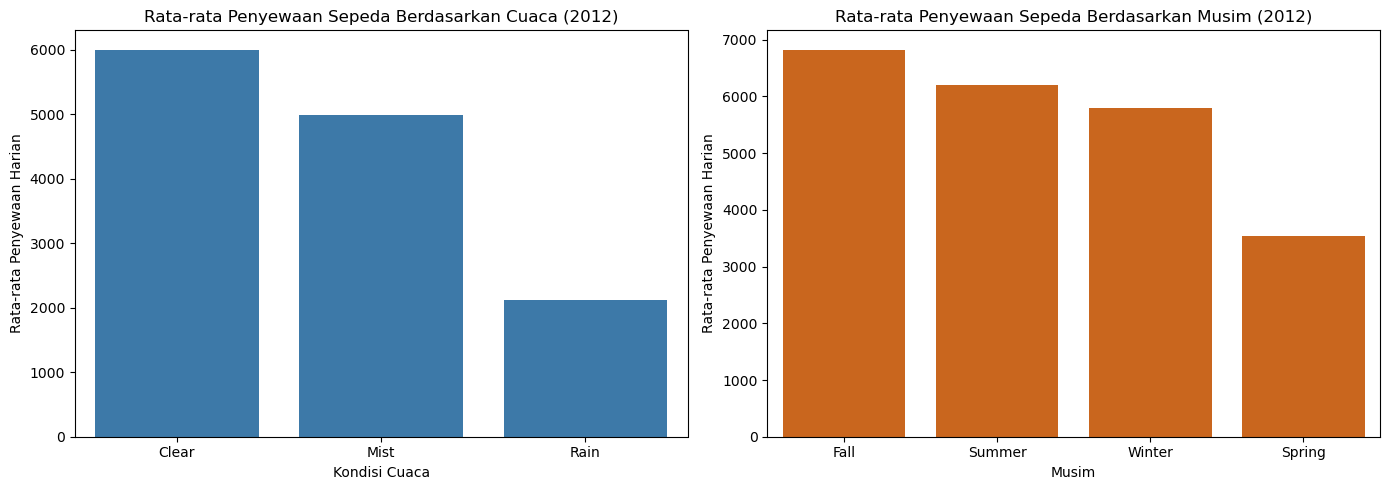

In [47]:
# Filter data khusus tahun 2012
df_day_2012 = df_day[df_day['year'] == '2012']

# Mengurutkan kategori dari rata-rata penyewaan tertinggi ke terendah
weather_order = (
    df_day_2012.groupby('weather_cond', observed=True)['total_count']
    .mean()
    .sort_values(ascending=False)
    .index
)
season_order = (
    df_day_2012.groupby('season', observed=True)['total_count']
    .mean()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Visualisasi 1: Dampak Cuaca (1 warna: Biru)
sns.barplot(
    data=df_day_2012,
    x='weather_cond',
    y='total_count',
    order=weather_order,
    estimator='mean',
    errorbar=None,
    ax=ax[0],
    color='#2b7bba'
)
ax[0].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Cuaca (2012)')
ax[0].set_xlabel('Kondisi Cuaca')
ax[0].set_ylabel('Rata-rata Penyewaan Harian')

# Visualisasi 2: Dampak Musim (1 warna: Oranye)
sns.barplot(
    data=df_day_2012,
    x='season',
    y='total_count',
    order=season_order,
    estimator='mean',
    errorbar=None,
    ax=ax[1],
    color='#e66101'
)
ax[1].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Musim (2012)')
ax[1].set_xlabel('Musim')
ax[1].set_ylabel('Rata-rata Penyewaan Harian')

plt.tight_layout()
plt.show()

In [48]:
# Menghitung % penurunan rata-rata penyewaan dari cuaca Clear ke Rain
clear_mean = weather_impact.loc['Clear', 'mean']
rain_mean = weather_impact.loc['Rain', 'mean']
pct_drop = ((clear_mean - rain_mean) / clear_mean) * 100
print(f"Penurunan rata-rata penyewaan saat Rain dibanding Clear: {pct_drop:.2f}%")

Penurunan rata-rata penyewaan saat Rain dibanding Clear: 64.59%


**Insight:**
- **Pengaruh Kondisi Cuaca (Tahun 2012)**
  - Rata-rata penyewaan tertinggi terjadi saat cuaca cerah (Clear) dengan angka mencapai kisaran 6.000 unit/hari. Saat cuaca berawan atau berkabut (Mist), minat bersepeda masih bertahan cukup tinggi di kisaran 5.000 unit/hari.
  - Ketika cuaca memburuk menjadi hujan (Rain), rata-rata penyewaan merosot tajam hingga menyentuh kisaran 2.100 unit/hari. Secara keseluruhan, terjadi penurunan rata-rata penyewaan sebesar 64,59% pada hari hujan dibandingkan hari cerah.
- **Pengaruh Musim (Tahun 2012)**
  - Rata-rata penyewaan tertinggi terjadi saat musim gugur (Fall) dengan angka mencapai kisaran 6.800 unit/hari, diikuti oleh musim panas (Summer) di kisaran 6.200 unit/hari, serta musim dingin (Winter) di kisaran 5.800 unit/hari.
  - Rata-rata penyewaan di musim semi berada di titik terendah dibandingkan musim lainnya, yakni hanya sekitar 3.500 unit/hari.


### **Pertanyaan 2:** Pada jam berapa puncak penyewaan sepeda terjadi antara pengguna biasa (casual) dan pengguna terdaftar (registered) pada hari kerja sepanjang tahun 2011-2012?

C:\Users\akunb\AppData\Local\Temp\ipykernel_17824\2263229060.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hourly_working = df_working.groupby('hour')[['casual_users', 'registered_users']].mean().reset_index()


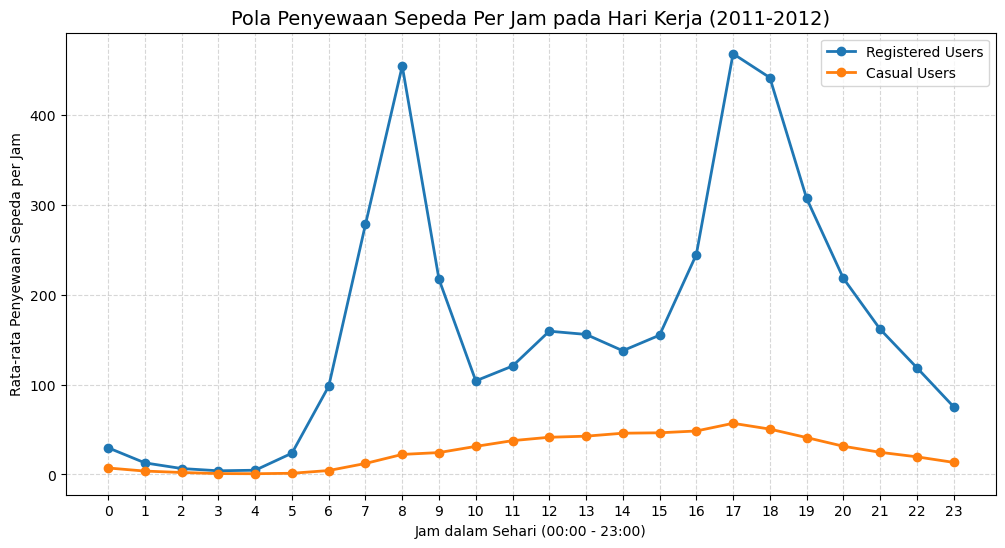

In [49]:
# Filter khusus hari kerja
df_working = df_hour[df_hour['workingday'] == 'Yes']
hourly_working = df_working.groupby('hour')[['casual_users', 'registered_users']].mean().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(hourly_working['hour'], hourly_working['registered_users'], label='Registered Users', marker='o', color='#1f77b4', linewidth=2)
plt.plot(hourly_working['hour'], hourly_working['casual_users'], label='Casual Users', marker='o', color='#ff7f0e', linewidth=2)

plt.title('Pola Penyewaan Sepeda Per Jam pada Hari Kerja (2011-2012)', fontsize=14)
plt.xlabel('Jam dalam Sehari (00:00 - 23:00)')
plt.ylabel('Rata-rata Penyewaan Sepeda per Jam')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight:**
- **Pengguna Terdaftar (Registered Users)**
  - Penyewaan melonjak tajam mulai jam 06.00 dan mencapai puncak pagi pada jam 08.00 dengan rata-rata sekitar 455-460 unit/jam, sebelum turun kembali ke kisaran 105 unit/jam pada jam 10.00.
  - Lonjakan tertinggi sepanjang hari terjadi pada jam 17.00 yakni mencapai sekitar 470 unit/jam dan bertahan sangat tinggi pada jam 18.00 (sekitar 440 unit/jam).
  - Dua puncak tertinggi pada jam 08.00 dan 17.00-18.00 mengonfirmasi bahwa pengguna terdaftar pada hari kerja didominasi oleh pekerja atau pelajar yang menggunakan sepeda untuk berangkat dan pulang beraktivitas.
- **Pengguna Biasa (Casual Users)**
  -  Tidak terjadi lonjakan pada jam berangkat kerja pagi hari. Penyewaan tumbuh bertahap sejak siang hari dan mencapai puncaknya pada jam 17.00 dengan rata-rata sekitar 60 unit/jam.
  - Sepanjang hari kerja, rata-rata penyewaan per jam pengguna biasa jauh berada di bawah pengguna terdaftar, dengan aktivitas yang lebih santai pada rentang siang hingga sore hari yakni dari jam 12.00 sampai 18.00.

### **Pertanyaan 3:** Berapa persentase pertumbuhan bulanan penyewaan sepeda dari tahun 2011 ke 2012, dan bulan apa yang mencatatkan penyewaan tertinggi di tahun 2012?

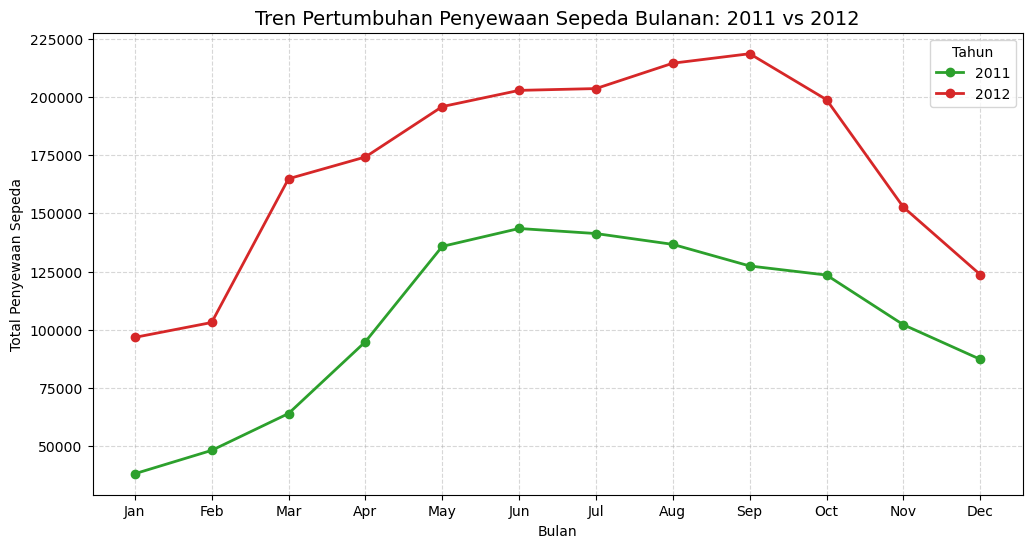

In [50]:
# Agregasi bulanan & perhitungan persentase pertumbuhan (2011 ke 2012)
monthly_rentals = df_day.groupby(['year', 'month'], observed=False)['total_count'].sum().unstack(level=0)
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_rentals = monthly_rentals.reindex(month_order)
monthly_rentals['growth_pct'] = ((monthly_rentals['2012'] - monthly_rentals['2011']) / monthly_rentals['2011']) * 100

# Visualisasi tren bulanan 2011 vs 2012
plt.figure(figsize=(12, 6))
plt.plot(monthly_rentals.index, monthly_rentals['2011'], label='2011', marker='o', linewidth=2, color='#2ca02c')
plt.plot(monthly_rentals.index, monthly_rentals['2012'], label='2012', marker='o', linewidth=2, color='#d62728')

plt.title('Tren Pertumbuhan Penyewaan Sepeda Bulanan: 2011 vs 2012', fontsize=14)
plt.xlabel('Bulan')
plt.ylabel('Total Penyewaan Sepeda')
plt.legend(title='Tahun')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight:**
- Sepanjang Januari hingga Desember, jumlah penyewaan sepeda di tahun 2012 selalu jauh lebih tinggi dibandingkan tahun 2011. Hal ini menunjukkan minat masyarakat untuk menyewa sepeda terus tumbuh pesat sepanjang tahun.
- Kenaikan paling mencolok pada tahun 2012 terjadi pada bulan Maret, dari sekitar 103.000 unit di bulan Februari menjadi sekitar 165.000 unit di bulan Maret. Dapat lebih dari dua setengah kali lipat dibandingkan Maret 2011 yang hanya sekitar 64.000 unit.
- Puncak tertinggi pada tahun 2012 terjadi pada bulan September yakni sekitar 220.000 unit, disusul ketat oleh bulan Agustus di sekitar 214.000 unit.
- Pada tahun 2011, penyewaan mencapai titik paling tinggi di pertengahan tahun, yakni pada bulan Juni sekitar 143.000 unit, tetapi perlahan turun hingga bulan Desember. Sebaliknya, pada tahun 2012 jumlah penyewaan terus naik dari awal tahun hingga mencapai puncaknya di bulan September.
- Pada kedua tahun tersebut, penyewaan mulai turun cukup tajam dari Oktober ke Desember seiring masuknya cuaca dingin. Meski begitu, jumlah sewa di Desember 2012 yakni sekitar 124.000 unit, tetap jauh lebih tinggi dibandingkan Desember 2011 yaitu sekitar 87.000 unit.

### **Pertanyaan 4:** Bagaimana perbedaan proporsi pengguna casual dan registered pada hari kerja dibandingkan akhir pekan sepanjang tahun 2012?

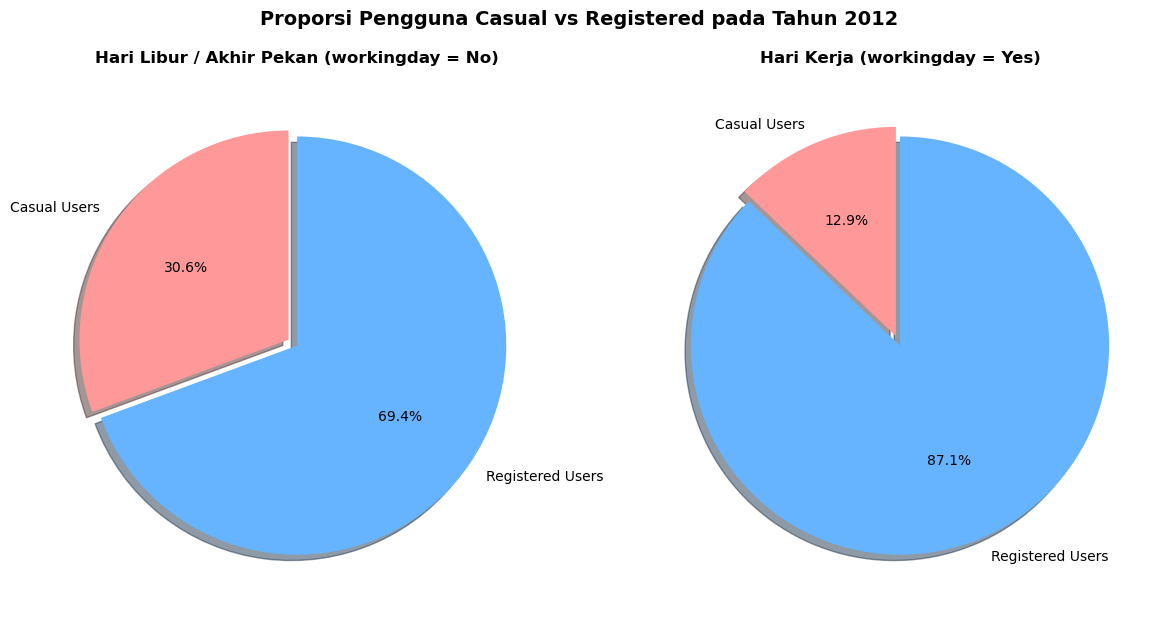

In [51]:
# Filter data 2012 & jumlahkan total casual dan registered (ditambah observed=False agar tidak memicu warning)
df_day_2012 = df_day[df_day['year'] == '2012']
workingday_sum = df_day_2012.groupby('workingday', observed=False)[['casual_users', 'registered_users']].sum()

labels = ['Casual Users', 'Registered Users']
colors = ['#ff9999', '#66b3ff']

# Membuat 2 Pie Chart berdampingan
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Pie Chart 1: Hari Libur / Akhir Pekan (workingday = No)
ax[0].pie(
    workingday_sum.loc['No'],
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=(0.05, 0),
    shadow=True
)
ax[0].set_title('Hari Libur / Akhir Pekan (workingday = No)', fontsize=12, fontweight='bold', pad=15)

# Pie Chart 2: Hari Kerja (workingday = Yes)
ax[1].pie(
    workingday_sum.loc['Yes'],
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=(0.05, 0),
    shadow=True
)
ax[1].set_title('Hari Kerja (workingday = Yes)', fontsize=12, fontweight='bold', pad=15)

# Judul Utama dinaikkan (y=1.02) agar memiliki jarak yang cukup
plt.suptitle('Proporsi Pengguna Casual vs Registered pada Tahun 2012', fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

**Insight:**
- **Pengguna Terdaftar (Registered Users)**
  - Pada hari kerja, pengguna terdaftar terhitung sebesar 87,1% dari total penyewaan, sementara pengguna biasa hanya sebesar 12,9%.
  - Sedangkan pada hari libur, walaupun persentase penyewaannya menurun dibandingkan hari kerja, pengguna terdaftar tetap menjadi penyumbang utama penyewaan pada hari libur atau akhir pekan dengan proporsi 69,4%.
- **Pengguna Biasa (Casual Users)**
  - Pada hari libur, penyewaan sepeda oleh pengguna biasa naik lebih dari 2x lipat dibandingkan hari kerja, yaitu dari 12.9% menjadi 30.6% dari total penyewaan.

Tingginya pengguna terdaftar pada hari kerja menguatkan temuan sebelumnya bahwa kelompok ini memanfaatkan sepeda sebagai sarana transportasi rutin. Sebaliknya, lonjakan persentase pengguna biasa di hari libur menunjukkan bahwa pengguna biasa cenderung menyewa sepeda untuk kebutuhan rekreasi, olahraga, atau wisata saat waktu luang.

## Analisis Lanjutan

Pada bagian ini, saya akan menerapkan teknik Clustering yakni Pengelompokan Manual / Binning pada variabel jam penyewaan. Tujuannya adalah untuk menyederhanakan data 24 jam menjadi beberapa periode waktu operasional yang lebih spesifik dan bermakna. Hal ini akan memudahkan kita dalam melihat pola tren perilaku pelanggan dan mengidentifikasi kapan peak hours dalam penyewaan sepeda.

Data jam (hour) akan dikelompokkan menjadi 4 kategori klaster utama:
1. **Morning Rush** (06:00 - 09:00): Jam sibuk di pagi hari saat orang mulai beraktivitas.
2. **Afternoon** (10:00 - 14:00): Jam siang hari dengan tingkat aktivitas normal.
3. **Evening Rush** (15:00 - 19:00): Jam sibuk di sore hari saat orang pulang beraktivitas.
4. **Night** (20:00 - 05:00): Jam istirahat malam dengan jumlah penyewaan paling sedikit.

In [52]:
# Mendefinisikan rentang waktu melalui fungsi
def categorize_time(hour):
    if 6 <= hour <= 9:
        return 'Morning Rush'
    elif 10 <= hour <= 14:
        return 'Afternoon'
    elif 15 <= hour <= 19:
        return 'Evening Rush'
    else:
        return 'Night' # Mencakup jam 20-23 dan 0-5

In [53]:
# Menerapkan fungsi ke dalam variabel baru bernama 'time_category'
df_hour['time_category'] = df_hour['hour'].apply(categorize_time)

In [54]:
# Mengubah tipe data menjadi categorical dengan urutan tertentu agar rapi saat divisualisasikan
category_order = ['Morning Rush', 'Afternoon', 'Evening Rush', 'Night']
df_hour['time_category'] = pd.Categorical(df_hour['time_category'], categories=category_order, ordered=True)

In [55]:
# Agregasi Data
# Menghitung total penyewaan (total_count) berdasarkan time_category
clustered_data = df_hour.groupby('time_category')['total_count'].sum().reset_index()

# Menampilkan tabel hasil agregasi
print(clustered_data)

  time_category  total_count
0  Morning Rush       629742
1     Afternoon       822562
2  Evening Rush      1284318
3         Night       556057


C:\Users\akunb\AppData\Local\Temp\ipykernel_17824\1536515312.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clustered_data = df_hour.groupby('time_category')['total_count'].sum().reset_index()


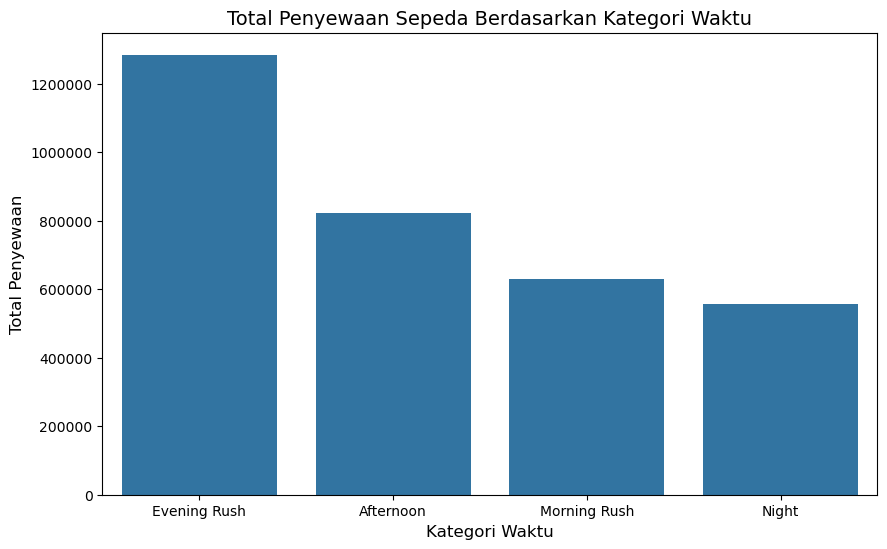

In [56]:
# Mengurutkan data dari total penyewaan terbesar ke terkecil
clustered_data = clustered_data.sort_values(by='total_count', ascending=False)

# Membuat visualisasi Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x='time_category',
    y='total_count',
    data=clustered_data,
    order=clustered_data['time_category'], # Memastikan urutan bar mengikuti hasil sorting
    color='#1f77b4' # Menggunakan satu warna solid (biru)
)

plt.title('Total Penyewaan Sepeda Berdasarkan Kategori Waktu', fontsize=14)
plt.xlabel('Kategori Waktu', fontsize=12)
plt.ylabel('Total Penyewaan', fontsize=12)
plt.ticklabel_format(style='plain', axis='y') # Menghilangkan format scientific (e+06) pada sumbu Y
plt.show()

**Insight:**
- Kategori Evening Rush (15:00 - 19:00) mencatatkan total penyewaan tertinggi secara signifikan, yakni mendekati 1,3 juta penyewaan. Hal ini menunjukkan bahwa puncak penggunaan sepeda terjadi pada waktu pulang kerja atau sekolah, yang sekaligus dimanfaatkan pelanggan untuk bersantai atau berolahraga di sore hari.
- Kategori Afternoon (10:00 - 14:00) menempati posisi kedua dengan total penyewaan melebihi 800.000. Angka ini mengindikasikan bahwa permintaan sepeda tetap kuat di luar jam berangkat dan pulang kerja, yang kemungkinan didorong oleh pengguna kasual (seperti wisatawan) maupun mobilitas makan siang.
- Kategori Morning Rush (06:00 - 09:00) berada di posisi ketiga dengan sekitar 630.000 penyewaan. Total penyewaan pada jam sibuk sore tercatat sekitar dua kali lipat lebih tinggi dibandingkan jam sibuk pagi. Selain karena rentang waktu klaster sore lebih panjang (5 jam dibanding 4 jam), pelanggan cenderung lebih santai menggunakan sepeda saat pulang beraktivitas dibandingkan saat berangkat di pagi hari.
- Kategori Night (20:00 - 05:00) mencatatkan total penyewaan paling rendah, yaitu di bawah angka 600.000 penyewaan. Meskipun memiliki durasi waktu paling panjang yakni kira-kira selama 10 jam, rendahnya angka ini sangat wajar karena sebagian besar masuk ke dalam jam istirahat masyarakat.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca dan musim terbukti sangat memengaruhi minat bersepeda sepanjang tahun 2012, di mana cuaca cerah (Clear) menghasilkan rata-rata penyewaan tertinggi sekitar 6.000 unit/hari dan musim gugur (Fall) menjadi musim teramai dengan kisaran 6.800 unit/hari. Sebaliknya, cuaca hujan (Rain) menjadi faktor penghambat utama yang menyebabkan rata-rata penyewaan anjlok tajam sebesar 64,59% hingga ke kisaran 2.100 unit/hari, sementara musim semi (Spring) mencatatkan performa terendah di kisaran 3.500 unit/hari.
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola jam sibuk yang sangat kontras antara kedua tipe pengguna pada hari kerja sepanjang 2011-2012. Pengguna terdaftar (registered) menunjukkan pola komuter (berangkat dan pulang kerja/sekolah) dengan dua lonjakan tajam pada pukul 08.00 yaitu sekitar 455-460 unit/jam dan mencapai puncak tertingginya pada pukul 17.00 yaitu sekitar 470 unit/jam, sedangkan pengguna biasa (casual) tidak memiliki lonjakan pagi dan baru mencapai puncaknya secara bertahap pada pukul 17.00 dengan rata-rata sekitar 60 unit/jam untuk aktivitas santai.
- **Conclusion pertanyaan 3:** Penyewaan sepeda mengalami pertumbuhan bulanan yang sangat pesat dari tahun 2011 ke 2012, di mana setiap bulan pada tahun 2012 selalu mencatatkan angka jauh di atas tahun sebelumnya dengan lonjakan paling drastis pada bulan Maret yang naik lebih dari 2,5 kali lipat yakni dari sekitar 64.000 menjadi 165.000 unit. Adapun puncak penyewaan tertinggi sepanjang tahun 2012 terjadi pada bulan September yang berhasil menyentuh angka sekitar 220.000 unit.
- **Conclusion pertanyaan 4:** Sepanjang tahun 2012, pengguna terdaftar (registered) selalu mendominasi total penyewaan baik pada hari kerja maupun akhir pekan, dengan porsi mencapai 87,1% pada hari kerja. Namun, pada hari libur atau akhir pekan terjadi pergeseran perilaku rekreasi yang membuat proporsi pengguna biasa (casual) melonjak lebih dari dua kali lipat menjadi 30,6%, sementara pengguna terdaftar berada di angka 69,4%.
- **Conclusion Analisis Lanjutan (Clustering)** : Pengelompokan kategori waktu menunjukkan bahwa periode Evening Rush mendominasi total penyewaan secara signifikan hingga mendekati 1,3 juta penyewaan, atau sekitar dua kali lipat lebih tinggi dibandingkan periode Morning Rush yang hanya mencatatkan sekitar 630.000 penyewaan. Aktivitas periode Afternoon juga terbukti tetap tinggi di posisi kedua dengan total melebihi 800.000 penyewaan, sedangkan periode Night mencatatkan angka terendah di bawah 600.000 penyewaan meskipun memiliki durasi terpanjang karena bertepatan dengan jam istirahat masyarakat.

**Rekomendasi Action Item:**
- Jadwalkan pemeliharaan rutin (maintenance) armada pada musim semi (Spring) atau saat prakiraan cuaca hujan deras ketika permintaan turun hingga 64,59%, serta luncurkan promo diskon khusus pada musim sepi untuk menjaga stabilitas penyewaan.
- Tingkatkan kapasitas armada dan kesiapan operasional secara bertahap mulai bulan Maret hingga mencapai puncaknya pada periode Agustus-September untuk memaksimalkan potensi pendapatan di bulan tersibuk.
- Fokuskan penambahan unit dan paket promo wisata/rekreasi di area taman atau tempat wisata pada akhir pekan untuk menjaring lonjakan pengguna casual, serta tawarkan program konversi keanggotaan (membership) bagi pengguna casual yang rutin menyewa.
- Pastikan distribusi dan pengisian ulang sepeda di stasiun-stasiun area perkantoran, kampus, dan titik transit selesai sebelum memasuki periode puncak Evening Rush (pukul 15:00) untuk menampung kemungkinan lonjakan penyewaan, serta alokasikan jadwal perawatan rutin dan pengecekan armada pada periode Night saat permintaan berada di titik terendah agar tidak mengganggu jam sibuk.

## Menyimpan Data untuk Membuat Dashboard

In [58]:
# Menggabungkan df_hour dan df_day menjadi satu dataframe utama (main_df)
main_df = pd.merge(
    left=df_hour,
    right=df_day[['dateday', 'weather_cond', 'casual_users', 'registered_users', 'total_count']],
    how='left',
    on='dateday',
    suffixes=('_hour', '_day')
)

# Menyimpan langsung ke folder Dashboard
main_df.to_csv("Dashboard/main_data.csv", index=False)
print("File main_data.csv berhasil disimpan di folder Dashboard!")

File main_data.csv berhasil disimpan di folder Dashboard!
